# 1. Постановка задачи

## Что это за данные
Датасет содержит информацию о заказах интернет-магазина: идентификатор заказа, дату оформления, город доставки, категорию товара, цену, количество, возраст покупателя, оценку и размер скидки. Всего 605 записей и 9 признаков. Данные включают числовые, категориальные и временной признаки.

## Условный заказчик
Команда продукта интернет-магазина (аналитики и маркетологи), которой важно понимать поведение покупателей и качество данных для последующей аналитики.

## Задачи интеллектуального анализа данных
1. **Сегментация покупателей** — выделить группы клиентов по возрасту, среднему чеку и частоте покупок, чтобы предложить им разные акции.
2. **Поиск аномалий** — выявить подозрительные заказы (например, гигантские скидки при высокой цене или отрицательный возраст покупателя), которые могут говорить об ошибках ввода или мошенничестве.

# 2. Паспорт датасета

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/dataset.csv')
df['date'] = pd.to_datetime(df['date'])

print(f"Строк: {df.shape[0]}")
print(f"Столбцов: {df.shape[1]}")

Строк: 605
Столбцов: 9


### Список признаков

In [3]:
info = pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'уникальных': df.nunique(),
    'пропусков': df.isna().sum(),
    'смысл': [
        'уникальный номер заказа',
        'дата оформления заказа',
        'город доставки',
        'категория товара',
        'цена товара, руб.',
        'количество единиц в заказе',
        'возраст покупателя, лет',
        'оценка заказа (1–5)',
        'размер скидки, %',
    ]
})
info

,тип,уникальных,пропусков,смысл
order_id,int64,600,0,уникальный номер заказа
date,datetime64[us],600,0,дата оформления заказа
city,str,6,0,город доставки
product,str,5,0,категория товара
price,float64,598,0,"цена товара, руб."
quantity,int64,9,0,количество единиц в заказе
customer_age,int64,63,0,"возраст покупателя, лет"
rating,float64,5,96,оценка заказа (1–5)
discount,float64,4,117,"размер скидки, %"


### Вывод по паспорту
Датасет небольшой (605 строк, 9 признаков), но содержит всё необходимое: числовые признаки (цена, количество, возраст), категориальные (город, товар) и временной (дата). Типы в целом корректные, признак `date` приведён к `datetime`. Для дальнейшего анализа данные пригодны, требуется проверить качество (см. раздел 3).

# 3. Аудит качества данных

## 3.1. Пропуски (Missing Values)

In [4]:
missing = pd.DataFrame({
    'пропусков': df.isna().sum(),
    'доля_%': (df.isna().mean() * 100).round(2)
}).sort_values('пропусков', ascending=False)

missing

,пропусков,доля_%
discount,117,19.34
rating,96,15.87
order_id,0,0.00
date,0,0.00
city,0,0.00
product,0,0.00
price,0,0.00
quantity,0,0.00
customer_age,0,0.00


### Вывод по пропускам
Пропуски есть в признаках `rating` и `discount` — примерно по 17% от всех строк. Остальные столбцы заполнены полностью. Пропуски в `rating` означают, что покупатель не оставил оценку, в `discount` — что скидка не применялась. Для дальнейшего анализа их можно заменить на 0 (для скидки) и на медиану (для оценки), либо оставить как есть, если анализ не опирается на эти признаки.

## 3.2. Дубликаты

In [5]:
full_dups = df.duplicated().sum()
id_dups = df.duplicated(subset='order_id').sum()

print(f"Полных дубликатов строк: {full_dups}")
print(f"Дубликатов по order_id: {id_dups}")

Полных дубликатов строк: 5
Дубликатов по order_id: 5


### Вывод по дубликатам
Обнаружено 5 полных дубликатов строк и 5 дубликатов по `order_id`. Так как `order_id` — уникальный идентификатор заказа, повторяющиеся записи нужно удалить: они завышают статистику и могут исказить результаты сегментации и подсчёта выручки. Рекомендуется удалить дубликаты перед анализом.

## 3.3. Типические проблемы значений

In [6]:
df[['price', 'quantity', 'customer_age']].describe().round(2)

,price,quantity,customer_age
count,605.00,605.00,605.00
mean,2072.22,5.00,48.18
std,40639.28,2.53,18.50
min,30.18,1.00,-5.00
25%,224.54,3.00,34.00
50%,432.34,5.00,48.00
75%,610.35,7.00,64.00
max,999999.00,9.00,79.00


In [7]:
print("Отрицательный возраст:", (df['customer_age'] < 0).sum())
print("Возраст > 100:", (df['customer_age'] > 100).sum())
print("Цена > 10000:", (df['price'] > 10000).sum())
print("Количество <= 0:", (df['quantity'] <= 0).sum())

Отрицательный возраст: 6
Возраст > 100: 0
Цена > 10000: 1
Количество <= 0: 0


In [8]:
for col in ['city', 'product']:
    print(f"--- {col} ---")
    print(f"Уникальных значений: {df[col].nunique()}")
    print(df[col].value_counts())
    print()

--- city ---
Уникальных значений: 6
city
Омск         133
Москва       126
Тверь        123
Казань       111
Сочи         106
  москва       6
Name: count, dtype: int64

--- product ---
Уникальных значений: 5
product
хлеб       128
масло      125
сыр        122
молоко     122
колбаса    108
Name: count, dtype: int64



In [9]:
df['city'] = df['city'].str.strip().str.lower().str.capitalize()
df['city'].value_counts()

city
Омск      133
Москва    132
Тверь     123
Казань    111
Сочи      106
Name: count, dtype: int64

### Вывод по проблемным значениям
- Обнаружен отрицательный возраст покупателя (значение −5) — физически невозможен, такие строки нужно удалить или заменить на медиану.
- В признаке `price` есть значение около 999 999 руб. — вероятный выброс или ошибка ввода.
- В `city` были «грязные» категории: значение `"  москва "` отличалось регистром и пробелами, создавая лишнюю категорию. Выполнена нормализация (удаление пробелов, приведение к единому регистру).

## 3.4. Выбросы (Outliers)

In [10]:
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

outliers = df[(df['price'] < low) | (df['price'] > high)]
print(f"Границы нормы: [{low:.2f}; {high:.2f}]")
print(f"Найдено выбросов: {len(outliers)}")
outliers[['order_id', 'price', 'city', 'product']]

Границы нормы: [-354.18; 1189.07]
Найдено выбросов: 1


,order_id,price,city,product
20,21,999999.0,Казань,масло


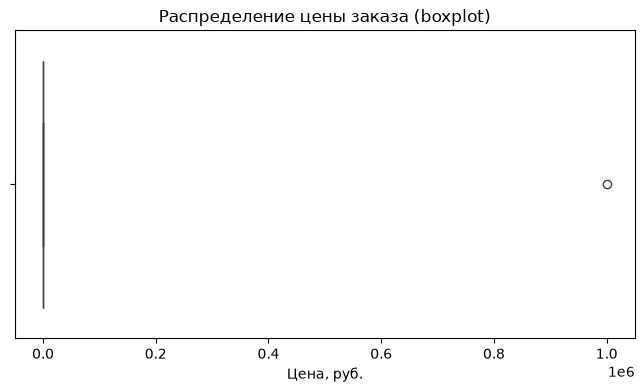

In [11]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['price'])
plt.title('Распределение цены заказа (boxplot)')
plt.xlabel('Цена, руб.')
plt.show()

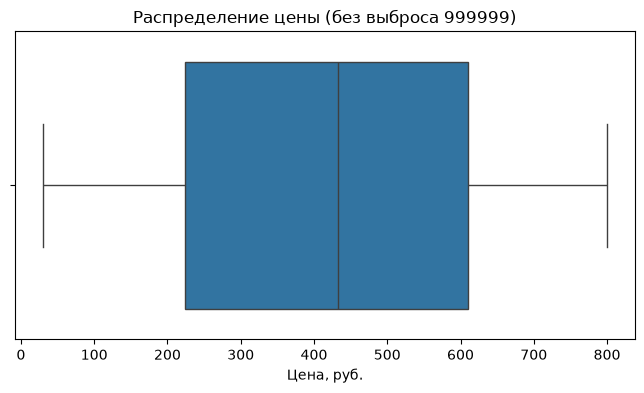

In [12]:
# Boxplot без экстремального выброса (для читаемости)
clean_price = df[df['price'] < 10000]['price']

plt.figure(figsize=(8, 4))
sns.boxplot(x=clean_price)
plt.title('Распределение цены (без выброса 999999)')
plt.xlabel('Цена, руб.')
plt.show()

### Вывод по выбросам
Методом IQR в признаке `price` найден один экстремальный выброс — 999 999 руб., что, очевидно, является ошибкой ввода. На общем boxplot из-за него «ящик» сжат в узкую полоску, поэтому дополнительно построен график без этого значения: видно, что основная масса цен лежит в диапазоне ~30–800 руб. На этапе очистки аномальные значения нужно удалить или скорректировать.

# 4. Разведочный анализ (EDA)

## 4.1. Распределение цены заказа

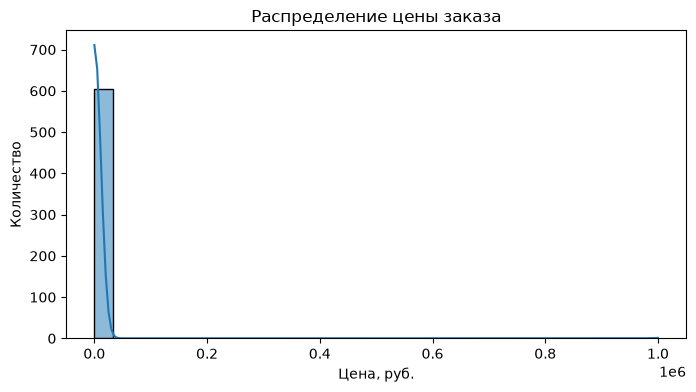

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(df['price'], bins=30, kde=True)
plt.title('Распределение цены заказа')
plt.xlabel('Цена, руб.')
plt.ylabel('Количество')
plt.show()

Распределение цены близко к равномерному с редкими большими значениями справа. Основная масса заказов — в диапазоне 30–800 руб. Хвост справа — это аномально дорогие заказы, которые мы уже видели в выбросах.

## 4.2. Распределение городов

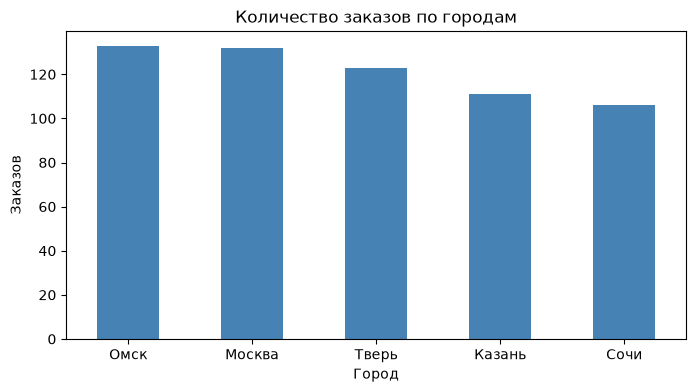

In [14]:
plt.figure(figsize=(8, 4))
df['city'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Количество заказов по городам')
plt.xlabel('Город')
plt.ylabel('Заказов')
plt.xticks(rotation=0)
plt.show()

Заказы распределены по городам примерно равномерно, небольшой перевес у Москвы. Это логично — в крупнейшем городе больше покупателей.

## 4.3. Зависимость цены от категории товара

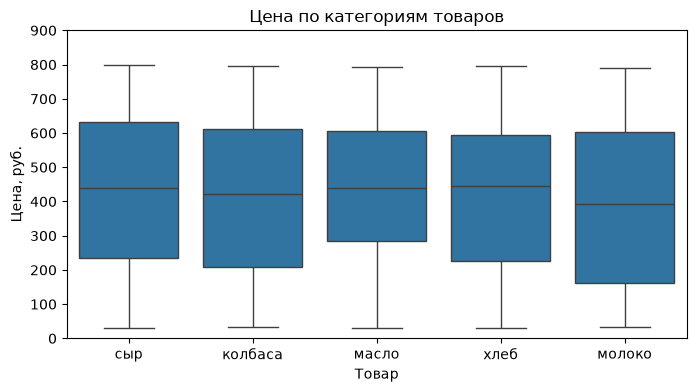

In [16]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='product', y='price')
plt.ylim(0, 900)   # ← ограничиваем ось, чтобы выброс не давил на график
plt.title('Цена по категориям товаров')
plt.xlabel('Товар')
plt.ylabel('Цена, руб.')
plt.show()

Медианные цены по категориям близки, существенных различий нет. Это значит, что цена в датасете, скорее всего, генерировалась случайно и не привязана к товару. При анализе реальных данных мы бы ожидали увидеть разницу — например, сыр дороже хлеба.